# Holter ECG 전처리 기록

- **목적**: 24시간 Holter 파형을 ① 전통 ML용 특징표, ② 1D-CNN·Transformer용 **30초 조각**(잡음 조각 제외, 24시간 전체)으로 만든다
- **데이터**: MUSIC (`data/music/subject-info.csv`, 파형 `/mnt/c/data/music/Holter_ECG/*.hea, *.dat`)
- **대상 정의 (기업 가이드)**: 생존(Cause of death=0) vs SCD(=3), 비심장성 사망·펌프부전 사망·심장이식·추적소실 제외 → 789명
- **원칙**: 기준값과 결정은 모두 아래 **결정 기록**에 남기고, 각 단계의 결과 인원은 `results/preprocess/flow.csv`에 저장한다

## 진행 상태

| 단계 | 내용 | 상태 | 날짜 |
|---|---|---|---|
| 1 | 기록 단위 품질 점검 (Record QC) | 진행 중 | |
| 2 | 신호 정제 (필터) | | |
| 3 | 잡음 구간 검출 (SQI) | | |
| 4 | R파 검출 · 박동 분류 · 리듬 예외 처리 | | |
| 5 | 특징 추출 → ML 특징표 | | |
| 6 | 딥러닝 입력 만들기 (30초 조각) | | |
| 7 | 데이터 분할 (임상 팀원과 공유) | | |
| 8 | 산출물 정리 · 데이터 사전 | | |

## 결정 기록 (Decision log)

> 기준을 정하거나 바꿀 때마다 한 줄씩 추가. 발표 때 "왜 이렇게 했나" 질문의 답이 된다.

| 날짜 | 단계 | 결정 | 이유 / 근거 | 영향 (인원) |
|---|---|---|---|---|
| 2026-10-23 | 대상 | 생존 vs SCD, 추적소실·이식·비심장성·펌프부전 사망 제외 | 기업 가이드 | 789명 (생존 695, SCD 94) |
| 2026-10-23 | 대상 | 나이 ">89"는 빼지 않고 표시만 (`age_over89`) | 팀 결정 대기. 1명 | |
| 2026-10-23 | 대상 | **변경**: 나이 ">89" 1명 제외 (위 "표시만" 결정을 바꿈) | 나이가 ">89"로 비식별 처리돼 정확한 값이 없음 | 파형 있음 741명 → 740명 |
| 2026-10-23 | 1 | QC는 10초 단위로 판정 | 10초 판정 3개를 묶으면 30초 판정도 만들 수 있음 | |
| 2026-10-23 | 6 | DL 입력은 30초 조각. 먼저 30초로 자르고 잡음 조각만 제외, 깨끗한 조각은 전부 사용 (24시간 전체) | 30초: DeepHHF 2026, Hannun 2019 / 전부 사용: K-REDEFINE 2025, Gadaleta 2023 | |
| 2026-10-23 | 6 | 박동 단위 입력(R파 ±360ms)과 박동 요약 보조 입력은 지금은 하지 않음. 30초만 진행 | 박동 단위는 리듬 정보가 사라지고 장기 예측 근거가 약함 (Oberdier 2025) | |
| 2026-10-23 | 1 | 평탄·멈춤·과대 진폭 기준을 논문 값으로 시작: 10초 창 범위 < 0.2 mV(평탄), 같은 값 ≥ 200 ms(멈춤), 범위 > 15 mV(과대 진폭). 결과가 이상하면 1-4 그림 확인 후 수정 | 비슷한 Holter 딥러닝 연구(DeepHHF 2026, K-REDEFINE 2025)와 MUSIC 논문(Ramírez 2017)은 구간 품질 기준을 밝히지 않음 → 일반 10초 ECG 품질 규칙(Moody 2011, PhysioNet Challenge 2011) 사용 | |
| 2026-10-23 | 1 | 멈춤 기준 200 ms (Moody 2011) 유지. 문제가 생기면 수정 | 1-4에서 P0001 멈춤 창 10개 확인: 8개는 저진폭·계단 모양 잡음 구간(나쁜 구간), 2개는 정상 기저선. 같은 값 길이 200~360 ms, 1초 이상 없음. 대안 Langley 2011(1초)은 이 잡음 구간을 통과시킴. 1-8 리듬 그룹별(특히 서맥·페이스메이커)로 재확인 | P0001: 창 1.6% (약 21분) |
| 2026-10-23 | 1 | **변경**: 멈춤 기준 200 ms (Moody 2011) → **1초 (Langley 2011)** | P0554(깨끗한 동리듬)에서 200 ms가 박동 사이 정상 기저선을 잡아 창 12.4% 제외 (10개 그림 모두 정상). 길이별 비교(X 유도): P0554 200 ms 12.39% / 400 ms 1.51% / 600 ms 0.08% / 1초 0.01%, P0001 잡음은 400 ms부터 0% → 멈춤 길이로는 잡음과 정상 기저선 구분 불가. 정상 손실이 0.1% 미만인 600 ms~1초 중 논문 근거가 있는 1초 선택. 저진폭 잡음은 3단계 SQI에서 처리. 1-8 전체 환자로 재확인 | P0554 제외 창 12.4% → 0.01% |
| 2026-10-23 | 1 | 평탄(< 0.2 mV)·과대 진폭(> 15 mV)·멈춤(1초)은 학회 논문 값(Moody 2011, Langley 2011) 유지 | 24시간 Holter용 진폭·평탄 기준을 숫자로 제시한 저널 논문을 찾지 못함 (Physiol Meas 2012 저널판은 접근 불가). 규칙 기반 사전 검사 방식 자체는 널리 쓰임 (Kuetche 2023). 숫자는 학회 논문, 적합성은 우리 데이터로 확인 (1-8) | |
| | | | | |

## 검토 중 (제안, 아직 결정 안 함)

> 결정하면 위 결정 기록으로 옮기고 여기서 지우기.

| 단계 | 제안 | 근거 | 언제 정하나 |
|---|---|---|---|
| 1 | `INVALID = -32768` (결측 표시값) — **보류** | WFDB 16비트 형식 규칙. 7명만 확인함 | 1-7 이후: 전체 헤더 fmt 동일 여부, -32768 개수, 최솟값·최댓값 확인 |
| 1 | `DUP_CORR = 0.99` (유도 중복) — **보류** | P0001 1명 발견 (0.999), 나머지 6명은 -0.7~0.4 | 1-7 이후: 전체 `max_lead_corr` 분포 확인 |
| 1 | 분석 가능 시간 제외 기준 18h → 20h | DeepHHF 2026은 20h 미만 제외 | 1-8에서 18h / 20h 제외 인원 비교 후 |
| 2, 6 | 200Hz 유지(다운샘플링 안 함), 필터를 용도별로 분리 (R파·HRV용 / DL 입력용) | Shiraishi 2023: 모델이 QRS·T파를 봄 | 2단계 |
| 6 | 저장은 int16 + 무손실 압축 | 정보 손실 없이 용량 절감 | 6단계 |
| 6 | 조각 길이 10초 vs 30초 비교 실험 | 잡음 분포·심박수·이벤트 길이 확인 후 | 1-8, 4단계 이후 |
| 평가 | 기준선: 가이드라인 ICD 기준 (LVEF ≤35% + NYHA II–III) | Shiraishi 2023 | 모델링 단계 |
| 대상 | 민감도 분석: 다른 사망을 0으로 포함한 버전 | 경쟁 위험 (Shiraishi 2023) | 팀과 논의 |

## 발견 사항

| 날짜 | 환자 | 내용 | 조치 |
|---|---|---|---|
| 2026-10-23 | P0001 | X·Y·Z 세 유도의 상관계수 0.999 → 사실상 같은 신호 | 1단계에서 유도 중복 검사 추가 |
| 2026-10-23 | 7명 | `Holter  rhythm` 코드 4 (코드표에 없음) 3명, 결측 4명. 파형은 있음 | 제외하지 않음. 4단계에서 파형으로 리듬 확인 |
| 2026-10-23 | P0001 | 멈춤(200 ms) 기준에 걸린 창 상당수가 저진폭(범위 < 1 mV)·계단 모양 잡음 구간. 기록 초반 0.2~1.2시간과 8~9시간에 몰림. 해상도(10 µV) 때문에 작은 신호는 값이 계단처럼 머묾 | 멈춤 기준이 "기계 멈춤"이 아니라 저진폭 잡음을 함께 잡고 있음. 1-8에서 전체 환자 확인, 3단계 SQI와 역할 정리 |
| 2026-10-23 | P0554 | 깨끗한 동리듬인데 같은 값이 200 ms~1초 이어지는 박동 사이 기저선이 많음 (해상도 10 µV). 200 ms 기준에서 창 12.4%가 잘못 걸림, 0~17시간에 고르게 분포 | 멈춤 기준을 1초로 변경 (결정 기록) |
| | | | |

## 참고 문헌

| 논문 | 입력 · 나누기 | 결과 | 참고한 점 |
|---|---|---|---|
| K-REDEFINE 2025 | 24h Holter, 9초 전부, 사전학습 인코더 고정 → 1D-ResNet | AUROC 0.74 (EF 결합 0.77) | 우리와 가장 비슷한 규모·문제 |
| DeepHHF 2026 | 24h Holter, 30초 (2분마다), CNN → Transformer | 0.80 (30초 1개 0.77) | 구조, 30초 조각 |
| Gadaleta 2023 | 10분 전부, 인코더 → LSTM | 0.80 (10분 0.77) | 길게 볼수록 좋아짐, 결합·보정 |
| Hannun 2019 | 30초, 환자당 1~2개, 1D-CNN | 리듬 분류 | 30초 + 1D-CNN 근거 (우리 문제엔 그대로 못 씀) |
| Shiraishi 2023 | 10초 12유도, CNN + LSTM, 심부전 SCD | 0.62 (기준과 결합 0.66) | QRS·T파 중요, 평가 방식 |
| Oberdier 2025 | 10초 12유도, R파 ±360ms 박동 단위 | 1일 이내 0.77 / 1개월~1년 0.57 | 박동 단위 방식 검토 (지금은 안 씀) |
| Langley 2011 (CinC 38:281) | 10초 12유도 (PhysioNet Challenge 2011) | 같은 값(constant voltage) 1초 이상 → 기록 불가 | 1단계 멈춤 기준 (200 ms에서 변경) |
| Moody 2011 (CinC 38:361) | 10초 12유도 (PhysioNet Challenge 2011), 규칙 기반 품질 판정 | 200 ms 이상 일정 → bad, 범위 < 0.2 mV 또는 > 15 mV → bad | 1단계 평탄·과대 진폭 기준 (멈춤 200 ms는 시도 후 1초로 변경) |
| Kuetche 2023 (Inform Med Unlocked 42:101375, 저널) | 10초, 여러 기기 (250~1000 Hz) | 0~1000 정규화 후 옆 샘플 차이 ≤ 1이면 일정, 1.5초 초과면 평탄선·포화. "CinC 2011의 평탄선·진폭 규칙은 현재 대부분 알고리즘의 사전 조건" (Moody·Langley 인용) | 규칙 방식의 저널 근거. 기준값 근거는 아님. 멈춤 1.5초 규칙은 시험 후보 |
| Bukhari 2025 (Comput Biol Med 196:110787, 저널) | UK Biobank 10초 12유도 | 진폭 기준을 데이터 분포로 계산, 정상 ECG 진폭은 5 mV 미만. 다른 집단에는 기준 재보정 권고 | 과대 진폭 15 mV가 정상 신호를 버리지 않는다는 참고, 데이터로 확인하는 과정의 근거 |
| Ramírez 2017 (JAHA, MUSIC) | MUSIC Holter 651명, 동리듬만 | 잡음 구간 기준 없음. 0.5 Hz 고역 + 40 Hz 저역 필터, 자동 검출 후 눈으로 확인 | 2단계 필터 근거 후보 |

## 0. 환경 설정

In [1]:
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import wfdb

# 한글 폰트
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

# 경로: notebooks/ 안에서 실행되든 프로젝트 루트에서 실행되든 동작하도록
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "music"
HOLTER = Path("/mnt/c/data/music/Holter_ECG")
OUT = ROOT / "results" / "preprocess"          # 전처리 결과물은 전부 여기에
OUT.mkdir(parents=True, exist_ok=True)

# ── 환자 흐름 기록: 단계마다 남은 인원을 flow.csv에 한 줄씩 남김 ──────────
FLOW = OUT / "flow.csv"

def record_flow(step, desc, d, label="label_scd"):
    """step 단계가 끝난 뒤 남은 환자 수(전체, 생존, SCD)를 flow.csv에 저장. 같은 step을 다시 돌리면 덮어씀"""
    row = {"step": step, "desc": desc, "n": len(d),
           "survivor": int((d[label] == 0).sum()), "scd": int((d[label] == 1).sum()),
           "date": date.today().isoformat()}
    flow = pd.read_csv(FLOW) if FLOW.exists() else pd.DataFrame(columns=row)
    flow = pd.concat([flow[flow["step"] != step], pd.DataFrame([row])]).sort_values("step")
    flow.to_csv(FLOW, index=False, encoding="utf-8-sig")
    return flow

---
# 1단계. 기록 단위 품질 점검 (Record-level QC)

**목표**: 환자 1명당 1줄짜리 `record_qc.csv`를 만들어 "이 기록을 분석에 써도 되는가, 안 되면 왜"를 남긴다.
필터링·R파 검출은 아직 하지 않고 **원본 숫자만** 본다. 10초 판정 결과는 6단계에서 30초 조각을 고를 때 다시 쓴다.

**판정 기준 (시작값. 바꾸면 결정 기록에 남길 것)**

| 항목 | 기준 | 의미 | 근거 |
|---|---|---|---|
| 창 길이 | 10초 (200Hz × 10 = 2000샘플) | 판정 단위 | Moody 2011 (Challenge 2011, 10초 기록), Behar 2013 (10초 조각 품질 판정) |
| 결측 | 창 안에 -32768 (**보류**: 전체 확인 전) | 기록 안 된 구간 | WFDB 형식 규칙 (논문 아님) |
| 평탄 | 최고−최저 < 0.2 mV | 전극 떨어짐 | Moody 2011 |
| 멈춤 | 같은 값 1초(200샘플) 이상 연속 | 평탄선·포화·기계 멈춤 | Langley 2011 (Moody 2011의 200 ms로 시작 → 정상 기저선이 걸려 변경, 결정 기록 참고) |
| 과대 진폭 | 최고−최저 > 15 mV | 움직임·전극 흔들림 | Moody 2011 |
| 유도 중복 | 유도 간 상관계수 > 0.99 (**보류**: 전체 분포 확인 전, 표시용) | 사실상 같은 신호 | **근거 없음** (P0001에서 발견, 데이터 분포로 결정 예정) |
| 제외 | 분석 가능 시간 < 18시간 (20시간 검토 중) | 기록이 너무 짧음 | 18h: 임상시험 Holter 기준 (근거 약함) / 20h: DeepHHF 2026 |

> Moody 2011은 10초 일반 ECG용이라 24시간 Holter와 환경이 다름. 비슷한 Holter 연구에 구간 기준이 없어서 이 값으로 시작하고, 이상하면 1-4 확인 후 수정 (결정 기록 2026-10-23)


**논문이 이 기준을 쓴 이유 (원문 확인)**

| 기준 | 논문 | 이유 |
|---|---|---|
| 10초 창 | Moody 2011, Behar 2013 | 대회(PhysioNet Challenge 2011) 데이터가 10초 기록이었음. Behar는 10초 조각 3만여 개에 품질을 사람이 직접 매겨 판정 모델을 만듦 |
| 평탄 (범위 < 0.2 mV) | Moody 2011 | 범위가 너무 작으면 전극이 제대로 붙지 않아 신호가 쓸모없을 가능성이 큼. 대회 학습 데이터에서 0.2 mV 미만이면 "사용 불가" 판정이 많았음 |
| 과대 진폭 (범위 > 15 mV) | Moody 2011 | 범위가 너무 크면 큰 잡음 스파이크나 심한 기저선 흔들림. 대회 판정자들이 대체로 "사용 불가"로 매겼고, 15 mV 초과면 사용 불가일 가능성이 높았음 |
| 멈춤 (같은 값 1초 이상) | Langley 2011 | 판정자가 "사용 불가"로 매긴 기록을 눈으로 보고 흔한 특징(평탄선, 포화, 기저선 흔들림 등)을 규칙으로 만듦. 실제 심전도는 잡음 때문에 값이 계속 변해서, 일정한 구간은 전극이 떨어진 것으로 봄 (Moody 2011). 왜 하필 1초인지는 원문에 따로 설명 없음 |

> 공통점: 셋 다 대회 학습 데이터에서 "사용 가능/불가" 판정을 가장 잘 맞히는 값을 경험적으로 고른 것. 10초 일반 ECG(휴대폰 기록) 기준이라 24시간 Holter와 환경이 다름 → 우리 데이터로 확인 후 조정 (멈춤 200 ms → 1초)

**이 단계에서 기록할 것**
- 기준값을 바꾸면 → 결정 기록
- 이상한 기록을 발견하면 → 발견 사항
- 소단계마다 → 📝 결과 메모
- 끝나면 → `flow.csv`(record_flow), 진행 상태 표의 상태·날짜, 📝 1단계 정리

In [2]:
# 1단계 기준값: 여기서만 바꾸고, 바꾸면 결정 기록에 남기기
WIN_SEC = 10            # Moody 2011, Behar 2013: 10초 단위 품질 판정
FLAT_PTP_MV = 0.2       # Moody 2011: 범위 < 0.2 mV → 평탄
STUCK_SEC = 1.0         # Langley 2011: 같은 값 1초 이상 → 멈춤 (Moody 200 ms에서 변경, 결정 기록 참고)
MAX_PTP_MV = 15.0       # Moody 2011: 범위 > 15 mV → 과대 진폭
DUP_CORR = 0.99         # 보류: 유도 간 상관계수 분포 확인 후 결정 (표시용, 제외 기준 아님)
MIN_VALID_H = 18.0      # 20.0 검토 중 (DeepHHF). 1-8에서 비교 후 결정
INVALID = -32768        # 보류: 전체 741명 헤더 fmt와 결측 존재 여부 확인 후 결정

### 1-1. 대상 환자 목록 (789명)

- `subject-info.csv` 읽기: `sep=";"`, `decimal=","`, 엑셀 오류 문자열(`#VALUE!` 등)은 결측으로
- 조건: `Cause of death` ∈ {0, 3}, `Exit of the study` ∉ {1, 2}
- 열 추가: `label_scd`, `age_over89` (표시만), `has_wave` (`HOLTER / f"{pid}.hea"` 존재 여부)
- 끝나면 `record_flow(1, "기업 가이드 대상", cohort)` 호출
- **같이 확인** (나중 단계에 필요, 📝 결과 메모에 적기)
  - 병원(센터)을 나타내는 열이 있는지 → 병원 단위 검증 가능 여부
  - LVEF, NYHA 열의 결측 개수 → 기준선 비교, 인코더 학습 가능 여부
  - `Holter  rhythm ` 열 분포 → 동리듬 / 심방세동 / 페이스메이커 인원

✅ **확인**: 789명 / SCD 94명 / 파형 있음 741명

In [3]:
# ① CSV 읽기 (992명)
df = pd.read_csv(DATA / "subject-info.csv", sep=";", decimal=",")

# ② 대상 조건: 생존(0) 또는 SCD(3), 추적소실·심장이식(Exit 1, 2) 제외
cond = (df["Cause of death"].isin([0, 3])) & (~df["Exit of the study"].isin([1, 2]))
cohort = df[cond].copy()

print("전체:", len(df), "→ 대상:", len(cohort))

# ③ 열 추가
cohort["label_scd"] = (cohort["Cause of death"] == 3).astype(int)          # SCD=1, 생존=0
cohort["age_over89"] = cohort["Age"].astype(str).str.strip() == ">89"      # 표시만 (빼지 않음)
cohort["Age"] = pd.to_numeric(cohort["Age"], errors="coerce")              # ">89"는 NaN이 됨
cohort["has_wave"] = cohort["Patient ID"].apply(lambda pid: (HOLTER / f"{pid}.hea").exists())

# ④ 인원 확인 → flow.csv에 기록
print("대상:", len(cohort), "/ SCD:", cohort["label_scd"].sum(),
      "/ 파형 있음:", cohort["has_wave"].sum(), "/ >89:", cohort["age_over89"].sum())
record_flow(1, "기업 가이드 대상", cohort)

# ⑤ 메모용 확인
wave = cohort[cohort["has_wave"]]

# 병원(센터) 열이 있는지: 열 이름 전체
print(list(df.columns))

# LVEF, NYHA 결측 수: 789명 기준 / 파형 있는 741명 기준
for col in ["LVEF (%)", "NYHA class"]:
    print(col, "| 789명 결측:", cohort[col].isna().sum(), "| 741명 결측:", wave[col].isna().sum())

# Holter 리듬 분포 (741명 기준)
print(wave["Holter  rhythm "].value_counts(dropna=False))


전체: 992 → 대상: 789
대상: 789 / SCD: 94 / 파형 있음: 741 / >89: 1
['Patient ID', 'Follow-up period from enrollment (days)', 'days_4years', 'Exit of the study', 'Cause of death', 'Age', 'Gender (male=1)', 'Weight (kg)', 'Height (cm)', 'Body Mass Index (Kg/m2)', 'NYHA class', 'Diastolic blood  pressure (mmHg)', 'Systolic blood pressure (mmHg)', 'HF etiology - Diagnosis', 'Diabetes (yes=1)', 'History of dyslipemia (yes=1)', 'Peripheral vascular disease (yes=1)', 'History of hypertension (yes=1)', 'Prior Myocardial Infarction (yes=1)', 'Prior implantable device', 'Prior Revascularization', 'Syncope', 'daily smoking (cigarretes/day)', 'smoke-free time (years)', 'cigarettes /year', 'alcohol consumption (standard units)', 'Albumin (g/L)', 'ALT or GPT (IU/L)', 'AST or GOT (IU/L)', 'Normalized Troponin', 'Total Cholesterol (mmol/L)', 'Creatinine (?mol/L)', 'Gamma-glutamil transpeptidase (IU/L)', 'Glucose (mmol/L)', 'Hemoglobin (g/L)', 'HDL (mmol/L)', 'Potassium (mEq/L)', 'LDL (mmol/L)', 'Sodium (mEq/L)

📝 **결과 메모** (2026-10-23)

- **인원**: 전체 992명 → 대상 789명 (생존 695 / SCD 94), 파형 있음 741명, 나이 ">89" 1명 → ✅ 기준과 일치. `flow.csv` step 1 저장
- **병원(센터) 열**: 없음 (103개 열 확인) → 병원 단위 검증은 불가
- **LVEF, NYHA 결측**: 둘 다 0명 (789명, 741명 모두)
- **Holter 리듬** (741명, 코드 뜻은 `subject-info_codes.csv`)

  | 코드 | 뜻 | 인원 |
  |---|---|---|
  | 0 | 동리듬 (Sinusal) | 540 |
  | 1 | 영구 심방세동 (Permanent AF) | 121 |
  | 2 | 심방조동 (Atrial flutter) | 1 |
  | 3 | 페이스메이커 | 72 |
  | 4 | **코드표에 없음** | 3 |
  | NaN | 결측 | 4 |

  → 심방세동·조동·페이스메이커 194명은 4단계(R파 검출·HRV)에서 예외 처리가 필요함. 코드 4 (3명)와 결측 (4명)은 확인 필요

### 1-2. 한 명(P0001)으로 헤더와 원본 값 보기

- `wfdb.rdrecord(path, physical=False, return_res=16)` → 정수 원본값 (빠르고, -32768을 그대로 볼 수 있음, 메모리 1/4)
- 확인할 값: `rec.fs`, `rec.sig_name`, `rec.sig_len`, `rec.adc_gain`, `rec.d_signal.dtype`
- mV 변환: `값 / rec.adc_gain[i]`

✅ **확인**: 200Hz, 유도 X·Y·Z, 약 22.9시간, gain 100, int16

In [4]:
rec = wfdb.rdrecord(str(HOLTER / "P0001"), physical=False, return_res=16)

print("fs:", rec.fs)                         # 샘플링 주파수
print("유도:", rec.sig_name)                  # 유도 이름
print("길이:", rec.sig_len, "샘플 =", rec.sig_len / rec.fs / 3600, "시간")
print("gain:", rec.adc_gain)                 # mV 변환값 (값 / gain = mV)
print("형식:", rec.fmt)                       # 저장 형식 (16이면 16비트)
print("dtype:", rec.d_signal.dtype, "/ shape:", rec.d_signal.shape)
print("최솟값:", rec.d_signal.min(axis=0), "/ 최댓값:", rec.d_signal.max(axis=0))


fs: 200
유도: ['X', 'Y', 'Z']
길이: 16460600 샘플 = 22.861944444444443 시간
gain: [100.0, 100.0, 100.0]
형식: ['16', '16', '16']
dtype: int16 / shape: (16460600, 3)
최솟값: [-741 -720 -739] / 최댓값: [1065 1083 1082]


📝 **결과 메모** (2026-10-23, P0001)

- fs 200Hz, 유도 X·Y·Z, 16,460,600샘플 = **22.86시간**, gain 100 (정수 ÷ 100 = mV), 형식 16비트, int16 → ✅ 기준과 일치
- 유도별 최솟값 / 최댓값 (정수, 괄호는 mV)

  | 유도 | 최솟값 | 최댓값 |
  |---|---|---|
  | X | -741 (-7.41) | 1065 (10.65) |
  | Y | -720 (-7.20) | 1083 (10.83) |
  | Z | -739 (-7.39) | 1082 (10.82) |

  - -32768 없음 → P0001은 결측 구간 없음 (INVALID 기준은 1-7 전체 확인 후 결정)
  - 세 유도의 최솟값·최댓값이 거의 같음 → 발견 사항의 유도 중복(상관 0.999)과 일치
  - 최댓값 약 10.8mV는 과대 진폭 기준(10mV, 10초 창 단위) 근처 → 1-3에서 걸리는 창 확인, 1-4에서 그림으로 확인

### 1-3. 10초 창으로 자르고 창마다 "못 쓰는 창" 판정 (P0001 한 명)

- `n_win = len(x) // 2000`, `x[:n_win*2000].reshape(n_win, 2000)` → 반복문 없이 창별 계산 (끝 자투리는 버림)
- 유도마다 네 가지(결측, 평탄, 멈춤, 과대 진폭)를 창별 True/False 배열로 만들고 `|`로 합치기
- 평탄과 과대 진폭은 둘 다 10초 창의 범위(최고−최저)로 판정 (Moody 2011). 기준값은 gain을 곱해 정수 단위로 비교
- 💡 멈춤: `np.diff(x) != 0`으로 값이 바뀌는 위치를 찾으면 같은 값이 이어진 구간의 길이를 구할 수 있음
- 유도별로 항목마다 "못 쓰는 창 비율(%)"을 출력해 보기

✅ **확인**: 정상적인 기록이면 대부분 1% 미만

In [5]:
fs = rec.fs
win = WIN_SEC * fs                      # 10초 = 2000샘플
stuck_len = int(STUCK_SEC * fs)         # 멈춤 기준 길이 (샘플 수)
n_win = rec.sig_len // win              # 끝 자투리는 버림

rows = []
bad = {}                                # 유도별 창 판정 (True = 못 쓰는 창)
for i, lead in enumerate(rec.sig_name):
    g = rec.adc_gain[i]
    w = rec.d_signal[:n_win * win, i].astype(np.int32).reshape(n_win, win)   # (창 개수, 2000)
    ptp = w.max(axis=1) - w.min(axis=1)                                      # 창마다 최고 − 최저

    # ① 결측: 창 안에 -32768이 하나라도 있음
    invalid = (w == INVALID).any(axis=1)
    # ② 평탄: 범위 < 0.2 mV
    flat = ptp < FLAT_PTP_MV * g
    # ③ 과대 진폭: 범위 > 15 mV
    big = ptp > MAX_PTP_MV * g
    # ④ 멈춤: 같은 값이 STUCK_SEC 이상 연속
    #    옆 샘플과 같으면 True → True가 (stuck_len - 1)개 연속이면 같은 값 stuck_len개
    same = (np.diff(w, axis=1) == 0).astype(np.int32)
    cs = np.concatenate([np.zeros((n_win, 1), np.int32), same.cumsum(axis=1, dtype=np.int32)], axis=1)
    stuck = ((cs[:, stuck_len - 1:] - cs[:, :-(stuck_len - 1)]) == stuck_len - 1).any(axis=1)

    bad[lead] = invalid | flat | big | stuck
    rows.append({"유도": lead, "결측%": invalid.mean() * 100, "평탄%": flat.mean() * 100,
                 "멈춤%": stuck.mean() * 100, "과대진폭%": big.mean() * 100,
                 "못씀(합)%": bad[lead].mean() * 100})

print("창 개수:", n_win, "/ 멈춤 기준:", stuck_len, "샘플")
pd.DataFrame(rows).round(2)

창 개수: 8230 / 멈춤 기준: 200 샘플


,유도,결측%,평탄%,멈춤%,과대진폭%,못씀(합)%
0,X,0.0,0.0,0.0,0.0,0.0
1,Y,0.0,0.0,0.0,0.0,0.0
2,Z,0.0,0.0,0.0,0.0,0.0


📝 **결과 메모** (2026-10-23, P0001, Moody 2011 기준)

- 창 8,230개 (10초), 멈춤 기준 40샘플 (200 ms)

  | 유도 | 결측% | 평탄% | 멈춤% | 과대진폭% | 못씀(합)% |
  |---|---|---|---|---|---|
  | X | 0.0 | 0.0 | 1.56 | 0.0 | 1.56 |
  | Y | 0.0 | 0.0 | 1.56 | 0.0 | 1.56 |
  | Z | 0.0 | 0.0 | 1.58 | 0.0 | 1.58 |

- 예전 시작값(평탄 표준편차 < 0.01 mV, 멈춤 1초, 과대 진폭 10 mV)과 비교: 과대진폭 0.02% → 0% (10.8 mV 창 2개가 15 mV 기준에서는 안 걸림), 멈춤 0% → 약 1.6% (약 128창, 약 21분)
  - 새로 걸린 멈춤 창 = 같은 값이 200 ms~1초 이어진 구간. 진짜 신호 멈춤인지, 해상도(0.01 mV) 때문에 정상 기저선이 걸린 것인지 **1-4에서 그림으로 확인 필요**
- ✅ 기준 "대부분 1% 미만"보다 약간 높음. P0001 제외 여부에는 영향 없음 (22.9시간 중 21분)

### 1-4. 못 쓰는 창 눈으로 확인하기

- 항목별로 걸린 창을 1~2개씩 골라 그려 보기 (`physical=True`로 해당 10초만 읽으면 편함)
- 기준이 너무 엄격하거나 느슨하면 기준값을 조정하고 **결정 기록**에 남기기

✅ **확인**: 걸린 창이 정말로 못 쓰는 신호인지

> ⚠️ 아래 코드는 멈춤 기준 **200 ms**를 검토할 때 쓴 셀. 이 확인 결과로 1-6에서 1초로 바꿈 (결정 기록). 1-8에서 다른 환자·항목 그림에 다시 활용 예정

In [6]:
# ⚠️ [200 ms 검토용] 멈춤 기준 200 ms(Moody 2011)를 검토할 때 쓴 셀. 지금 기준은 1초(Langley 2011)
#    → 지금 실행하면 1초 기준 결과가 나옴. 200 ms 때 그림은 results/preprocess/figures/*stuck200ms*.png
lead_i = 0                                   # X 유도 (세 유도가 같은 신호라 하나만 봄)
g = rec.adc_gain[lead_i]
x = rec.d_signal[:n_win * win, lead_i].astype(np.int32).reshape(n_win, win)

def longest_run(row):
    """같은 값이 가장 길게 이어진 구간의 (시작 위치, 길이)"""
    change = np.flatnonzero(np.diff(row) != 0) + 1     # 값이 바뀌는 위치
    starts = np.r_[0, change]
    ends = np.r_[change, len(row)]
    k = np.argmax(ends - starts)
    return starts[k], ends[k] - starts[k]

# 창마다 가장 긴 "같은 값" 구간
runs = np.array([longest_run(r) for r in x])          # (창 개수, 2) = 시작, 길이
stuck_x = runs[:, 1] >= stuck_len
print("멈춤 창:", stuck_x.sum(), "개 (1-3 결과와 같아야 함)")
print("걸린 창의 가장 긴 같은 값 길이 (ms)")
print(pd.Series(runs[stuck_x, 1] * 1000 / fs).describe().round(0))

# 걸린 창 3개를 무작위로 골라 그리기: 왼쪽 10초 전체, 오른쪽 확대 (빨간 부분 = 같은 값 구간)
rng = np.random.default_rng(0)
cand = np.flatnonzero(stuck_x)
if len(cand) == 0:
    print("멈춤에 걸린 창이 없어요 → 그릴 창 없음")
else:
    pick = rng.choice(cand, size=min(10, len(cand)), replace=False)   # 10개보다 적으면 있는 만큼
    t = np.arange(win) / fs
    fig, axes = plt.subplots(len(pick), 2, figsize=(14, 3 * len(pick)), squeeze=False)
    for ax, k in zip(axes, pick):
        s, L = runs[k]
        y = x[k] / g                                       # mV
        ax[0].plot(t, y, lw=0.6)
        ax[0].axvspan(s / fs, (s + L) / fs, color="red", alpha=0.3)
        ax[0].set_title(f"창 {k} (시작 {k * WIN_SEC / 3600:.2f}시간) · 같은 값 {L * 1000 / fs:.0f} ms")
        a, b = max(0, s - 200), min(win, s + L + 200)       # 앞뒤 1초
        ax[1].plot(t[a:b], y[a:b], ".-", lw=0.6, ms=2)
        ax[1].axvspan(s / fs, (s + L) / fs, color="red", alpha=0.3)
        ax[1].set_title("확대 (앞뒤 1초)")
        ax[0].set_ylabel("mV")
    plt.tight_layout()
    plt.show()


멈춤 창: 0 개 (1-3 결과와 같아야 함)
걸린 창의 가장 긴 같은 값 길이 (ms)
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
dtype: float64
멈춤에 걸린 창이 없어요 → 그릴 창 없음


📝 **결과 메모** (2026-10-23, P0001, X 유도)

- 결측·평탄·과대진폭은 0%라 확인할 창 없음 → **멈춤 창(128개)만 확인**
- 걸린 창의 가장 긴 같은 값 길이: 200~360 ms (중앙값 235 ms), **1초 이상 없음** → 기계가 멈춘 구간은 없음
- 무작위 10개 그림 확인 (`size=10`, seed 0)

  | 분류 | 개수 | 창 (시작 시간) |
  |---|---|---|
  | 정상인데 걸림 (박동 사이 기저선) | 2 | 5838 (16.22h), 5848 (16.24h) |
  | 품질 나쁨 (저진폭, 뚜렷한 QRS 없음, 계단 모양) | 6 | 67, 75, 84, 277, 364, 436 (0.19~1.21h) |
  | 애매하지만 품질 나쁜 쪽 | 2 | 2882 (8.01h), 3212 (8.92h) |

- 해석: 200 ms 기준은 원래 의도(기계 멈춤)가 아니라 **저진폭 잡음 구간**을 함께 잡고 있음. 정상 구간 손실은 일부(10개 중 2개, 기록의 약 0.3%로 추정)
- 결정: 200 ms 유지, 문제가 생기면 수정 (결정 기록). 1-8에서 리듬 그룹별 멈춤% 확인
- ⚠️ **이후 변경**: 1-6에서 P0554 정상 기저선이 12.4% 걸려 멈춤 기준을 **1초 (Langley 2011)**로 바꿈 (결정 기록, 1-6 메모)
- 그림 (200 ms 기준, 셀을 다시 실행해 노트북 출력은 사라짐): `results/preprocess/figures/1-4_P0001_stuck200ms_3windows.png`, `results/preprocess/figures/1-4_P0001_stuck200ms_10windows.png`

### 1-5. 유도 중복 검사

- `np.corrcoef(d[::50].T)` → 유도끼리 상관계수 (50샘플마다 하나씩 뽑아도 결과 같고 빠름)
- 기록할 값: `max_lead_corr`, `n_eff_leads` (0.99 넘게 닮은 유도는 하나로 센 실제 유도 수)

✅ **확인**: P0001은 `n_eff_leads = 1`

In [7]:
d = rec.d_signal[::50].astype(np.float32)          # 50샘플마다 하나 (0.25초 간격) → 빠름
C = np.corrcoef(d.T)                                # 유도 × 유도 상관계수 표
print(pd.DataFrame(C, index=rec.sig_name, columns=rec.sig_name).round(4))

# 가장 높은 유도 간 상관 (자기 자신 제외). 뒤집힌 복사본(-0.99)도 같은 정보라 절댓값 사용
iu = np.triu_indices(len(C), k=1)
max_lead_corr = np.abs(C[iu]).max()

# 실제 유도 수: 이미 센 유도와 DUP_CORR 넘게 닮은 유도는 같은 것으로 셈
keep = []
for j in range(len(C)):
    if all(abs(C[j, k]) <= DUP_CORR for k in keep):
        keep.append(j)
n_eff_leads = len(keep)
print("max_lead_corr:", round(max_lead_corr, 4), "/ n_eff_leads:", n_eff_leads)

# 참고: 아예 똑같은 숫자인지 (복사본인지)
for a, b in [(0, 1), (0, 2), (1, 2)]:
    same = (rec.d_signal[:, a] == rec.d_signal[:, b]).mean() * 100
    print(f"{rec.sig_name[a]}-{rec.sig_name[b]} 값이 완전히 같은 샘플: {same:.1f}%")


        X       Y       Z
X  1.0000  0.9993  0.9980
Y  0.9993  1.0000  0.9994
Z  0.9980  0.9994  1.0000
max_lead_corr: 0.9994 / n_eff_leads: 1
X-Y 값이 완전히 같은 샘플: 35.1%
X-Z 값이 완전히 같은 샘플: 27.1%
Y-Z 값이 완전히 같은 샘플: 35.1%


In [8]:
# 다른 환자 20명: 유도 수와 유도 간 상관
def lead_corr(pid):
    r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16)
    d = r.d_signal[::50].astype(np.float32)
    C = np.corrcoef(d.T)
    iu = np.triu_indices(len(C), k=1)
    return {"pid": pid, "n_leads": r.n_sig, "유도": r.sig_name,
            "duration_h": round(r.sig_len / r.fs / 3600, 1),
            "max_lead_corr": round(float(np.abs(C[iu]).max()), 3),
            "유도쌍 상관": np.round(C[iu], 2).tolist()}

sample = wave.sample(20, random_state=0)["Patient ID"]      # 파형 있는 741명 중 무작위 20명
t0 = time.time()
res = pd.DataFrame([lead_corr(p) for p in sample])
res = res.merge(wave[["Patient ID", "Holter  rhythm "]], left_on="pid", right_on="Patient ID").drop(columns="Patient ID")
print(f"걸린 시간: {time.time() - t0:.0f}초")
print("max_lead_corr > 0.99인 환자:", (res["max_lead_corr"] > DUP_CORR).sum(), "/ 20명")
res.sort_values("max_lead_corr", ascending=False)


걸린 시간: 10초
max_lead_corr > 0.99인 환자: 0 / 20명


,pid,n_leads,유도,duration_h,max_lead_corr,유도쌍 상관,Holter rhythm
18,P0537,3,"[X, Y, Z]",22.2,0.723,"[0.06, 0.72, -0.02]",3.0
16,P0854,3,"[X, Y, Z]",24.0,0.494,"[0.31, 0.49, 0.1]",0.0
12,P0074,3,"[X, Y, Z]",23.6,0.472,"[-0.13, 0.47, -0.03]",3.0
13,P0217,3,"[X, Y, Z]",23.0,0.459,"[-0.46, 0.12, -0.23]",1.0
5,P0937,3,"[X, Y, Z]",24.0,0.424,"[-0.35, 0.21, -0.42]",0.0
7,P0982,3,"[X, Y, Z]",24.0,0.416,"[-0.01, 0.08, -0.42]",0.0
14,P0272,3,"[X, Y, Z]",21.7,0.375,"[-0.06, -0.37, -0.24]",0.0
15,P0235,3,"[X, Y, Z]",23.4,0.331,"[-0.1, 0.1, -0.33]",0.0
4,P0554,3,"[X, Y, Z]",20.0,0.314,"[0.3, 0.12, 0.31]",0.0
3,P0041,3,"[X, Y, Z]",24.0,0.297,"[-0.02, 0.3, -0.09]",0.0


📝 **결과 메모** (2026-10-23)

- **P0001**: 유도 간 상관 X-Y 0.9993, X-Z 0.9980, Y-Z 0.9994 → `max_lead_corr` 0.9994, `n_eff_leads` = 1 ✅
  - 값이 완전히 같은 샘플은 27~35%뿐 → 단순 채널 복사가 아니라 **모양이 거의 같은 신호** (전극 부착·기기 설정 문제 추정, 원인은 데이터로 확인 불가)
  - 파일상 3유도지만 실제 정보는 1유도
- **무작위 20명** (`wave.sample(20, random_state=0)`): 모두 3유도(X·Y·Z), `max_lead_corr` 0.10~0.72, **0.99 초과 0명**
  - 가장 높은 P0537(0.72)은 페이스메이커 환자 → 자극 신호가 세 유도에 같이 찍힌 영향 가능
  - 기록 길이 20.0~24.0시간 (P0554 = 20.0시간, 20h 기준이면 경계)
- 결론: 유도 중복은 드묾 (20명 중 0명). 정확한 인원과 2유도 환자 수(논문상 약 3%)는 1-7 전체 실행에서 확인. `DUP_CORR` 보류는 그때 결정

### 1-6. 함수로 묶어서 몇 명 시험

- 1-2 ~ 1-5를 `qc_record(pid) -> dict` 함수 하나로 묶기
  - 기록할 값: `fs`, `n_leads`, `duration_h`, 유도별 항목별 %, `max_lead_corr`, `n_eff_leads`,
    `valid_h` (유도 중 **하나라도** 쓸 수 있는 창 × 10초 ÷ 3600), `valid_all_leads_h` (**모든** 유도가 쓸 수 있는 창 기준)
  - 창별 판정 배열은 `OUT / "window_qc" / f"{pid}.npz"`로 저장 (3단계, 6단계에서 다시 씀)
- 먼저 5명만 돌려 보고 결과 표 확인

✅ **확인**: 1명당 약 1초, 오류 없음

In [9]:
WIN_DIR = OUT / "window_qc"                  # 환자별 창 판정 저장 폴더 (3단계, 6단계에서 다시 씀)
WIN_DIR.mkdir(exist_ok=True)

def window_flags(x, g, n_win, win, stuck_len):
    """한 유도의 10초 창별 판정 (1-3과 같은 계산). 결측, 평탄, 과대 진폭, 멈춤"""
    w = x[:n_win * win].astype(np.int32).reshape(n_win, win)
    ptp = w.max(axis=1) - w.min(axis=1)
    invalid = (w == INVALID).any(axis=1)
    flat = ptp < FLAT_PTP_MV * g
    big = ptp > MAX_PTP_MV * g
    same = (np.diff(w, axis=1) == 0).astype(np.int32)
    cs = np.concatenate([np.zeros((n_win, 1), np.int32), same.cumsum(axis=1, dtype=np.int32)], axis=1)
    stuck = ((cs[:, stuck_len - 1:] - cs[:, :-(stuck_len - 1)]) == stuck_len - 1).any(axis=1)
    return invalid, flat, big, stuck

def qc_record(pid):
    """환자 1명의 1단계 QC 결과 (1줄짜리 dict). 창별 판정은 npz로 저장"""
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16)
    fs = rec.fs
    win = WIN_SEC * fs
    stuck_len = int(STUCK_SEC * fs)
    n_win = rec.sig_len // win
    out = {"pid": pid, "fs": fs, "n_leads": rec.n_sig, "leads": "".join(rec.sig_name),
           "duration_h": rec.sig_len / fs / 3600}

    # 유도별 창 판정 (1-3)
    flags = {"invalid": [], "flat": [], "big": [], "stuck": []}
    for i, lead in enumerate(rec.sig_name):
        for k, v in zip(flags, window_flags(rec.d_signal[:, i], rec.adc_gain[i], n_win, win, stuck_len)):
            flags[k].append(v)
            out[f"{lead}_{k}%"] = v.mean() * 100
    flags = {k: np.array(v) for k, v in flags.items()}                 # 각각 (유도 수, 창 수)
    bad = flags["invalid"] | flags["flat"] | flags["big"] | flags["stuck"]

    # 분석 가능 시간
    out["valid_h"] = (~bad).any(axis=0).sum() * WIN_SEC / 3600          # 유도 중 하나라도 쓸 수 있는 창
    out["valid_all_leads_h"] = (~bad).all(axis=0).sum() * WIN_SEC / 3600  # 모든 유도가 쓸 수 있는 창

    # 유도 중복 (1-5)
    C = np.corrcoef(rec.d_signal[::50].astype(np.float32).T)
    iu = np.triu_indices(rec.n_sig, k=1)
    out["max_lead_corr"] = np.nanmax(np.abs(C[iu]))
    keep = []
    for j in range(rec.n_sig):
        if all(not abs(C[j, k]) > DUP_CORR for k in keep):
            keep.append(j)
    out["n_eff_leads"] = len(keep)

    np.savez_compressed(WIN_DIR / f"{pid}.npz", leads=np.array(rec.sig_name), **flags)
    return out

# 5명 시험: P0001 + 리듬·길이가 다른 4명 (1-5의 20명 중에서)
test = ["P0001", "P0537", "P0217", "P0554", "P0854"]   # P0537 페이스메이커, P0217 심방세동, P0554 20.0h, P0854 동리듬
rows = []
for pid in test:
    t0 = time.time()
    r = qc_record(pid)
    r["sec"] = time.time() - t0
    rows.append(r)
qc5 = pd.DataFrame(rows).set_index("pid")
qc5.round(2).T


pid,P0001,P0537,P0217,P0554,P0854
fs,200,200,200,200,200
n_leads,3,3,3,3,3
leads,XYZ,XYZ,XYZ,XYZ,XYZ
duration_h,22.86,22.22,22.96,19.99,24.0
X_invalid%,0.0,0.0,0.0,0.0,0.0
X_flat%,0.0,0.0,0.0,0.0,0.0
X_big%,0.0,0.0,0.05,0.06,0.0
X_stuck%,0.0,0.01,0.01,0.01,0.01
Y_invalid%,0.0,0.0,0.0,0.0,0.0
Y_flat%,0.0,0.0,0.0,0.0,0.0


#### (참고) 멈춤 기준 200 ms 검토용 셀 2개

- P0554 멈춤 창 확인, 멈춤 기준 길이별 비교 (200 ms ~ 1초)
- 결정 기록 "멈춤 기준 200 ms → 1초 변경"의 근거. 지금 기준(1초)으로 다시 실행하면 결과가 달라짐
- 200 ms 때 결과는 아래 📝 결과 메모와 `results/preprocess/figures/1-6_P0554_stuck200ms_*.png`에 보관

P0554 멈춤 창: 1 / 7197 개
걸린 창의 가장 긴 같은 값 길이 (ms)
count       1.0
mean     1005.0
std         NaN
min      1005.0
25%      1005.0
50%      1005.0
75%      1005.0
max      1005.0
dtype: float64


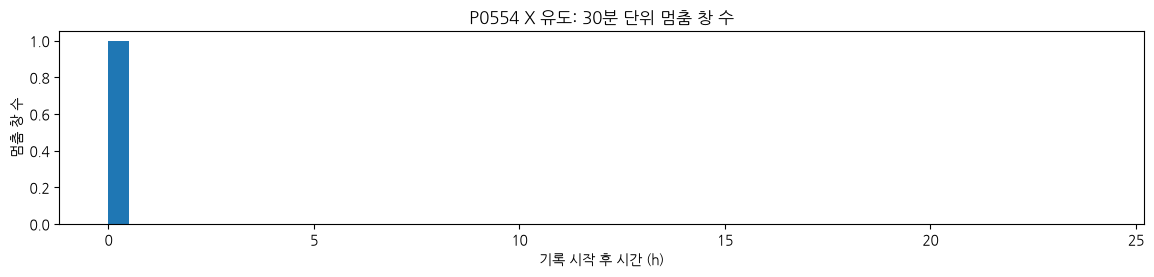

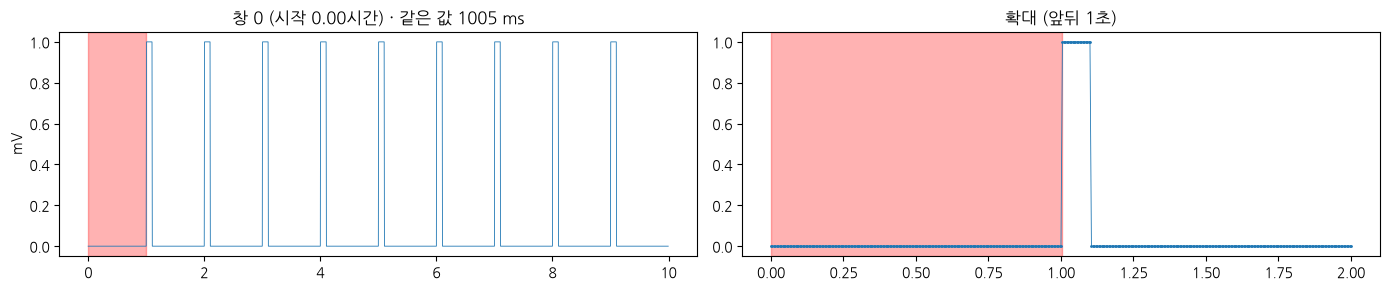

In [10]:
# ⚠️ [200 ms 검토용] 멈춤 기준 200 ms(Moody 2011)를 검토할 때 쓴 셀. 지금 기준은 1초(Langley 2011)
#    → 지금 실행하면 1초 기준 결과가 나옴. 200 ms 때 그림은 results/preprocess/figures/*stuck200ms*.png
# P0554 멈춤 창 확인 (1-4와 같은 방식)
pid = "P0554"
r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16)
lead_i = 0                                            # X 유도 (멈춤 12.4%로 가장 높음)
g = r.adc_gain[lead_i]
nw = r.sig_len // win
xx = r.d_signal[:nw * win, lead_i].astype(np.int32).reshape(nw, win)

runs_p = np.array([longest_run(row) for row in xx])
stuck_p = runs_p[:, 1] >= stuck_len
print(pid, "멈춤 창:", stuck_p.sum(), "/", nw, "개")
print("걸린 창의 가장 긴 같은 값 길이 (ms)")
print(pd.Series(runs_p[stuck_p, 1] * 1000 / fs).describe().round(0))

# ① 멈춤 창이 어느 시간대에 몰려 있나
plt.figure(figsize=(14, 2.5))
plt.hist(np.flatnonzero(stuck_p) * WIN_SEC / 3600, bins=np.arange(0, 24.5, 0.5))
plt.xlabel("기록 시작 후 시간 (h)")
plt.ylabel("멈춤 창 수")
plt.title(f"{pid} X 유도: 30분 단위 멈춤 창 수")
plt.show()

# ② 걸린 창 10개 그림 (빨간 부분 = 같은 값 구간)
rng = np.random.default_rng(0)
cand = np.flatnonzero(stuck_p)
if len(cand) == 0:
    print("멈춤에 걸린 창이 없어요 → 그릴 창 없음")
else:
    pick = rng.choice(cand, size=min(10, len(cand)), replace=False)   # 10개보다 적으면 있는 만큼
    t = np.arange(win) / fs
    fig, axes = plt.subplots(len(pick), 2, figsize=(14, 3 * len(pick)), squeeze=False)
    for ax, k in zip(axes, pick):
        s, L = runs_p[k]
        y = xx[k] / g
        ax[0].plot(t, y, lw=0.6)
        ax[0].axvspan(s / fs, (s + L) / fs, color="red", alpha=0.3)
        ax[0].set_title(f"창 {k} (시작 {k * WIN_SEC / 3600:.2f}시간) · 같은 값 {L * 1000 / fs:.0f} ms")
        a, b = max(0, s - 200), min(win, s + L + 200)
        ax[1].plot(t[a:b], y[a:b], ".-", lw=0.6, ms=2)
        ax[1].axvspan(s / fs, (s + L) / fs, color="red", alpha=0.3)
        ax[1].set_title("확대 (앞뒤 1초)")
        ax[0].set_ylabel("mV")
    plt.tight_layout()
    plt.show()


In [11]:
# ⚠️ [200 ms 검토용] 멈춤 기준 200 ms(Moody 2011)를 검토할 때 쓴 셀. 지금 기준은 1초(Langley 2011)
#    → 지금 실행하면 1초 기준 결과가 나옴. 200 ms 때 그림은 results/preprocess/figures/*stuck200ms*.png
# 멈춤 기준 길이별로 걸리는 창 비율 비교 (X 유도)
for ms in [200, 300, 400, 500, 600, 800, 1000]:
    L = ms * fs // 1000                                   # ms → 샘플 수
    p1 = (runs[:, 1] >= L).mean() * 100                    # P0001
    p2 = (runs_p[:, 1] >= L).mean() * 100                  # P0554
    print(f"{ms:5} ms | P0001: {p1:5.2f}% | P0554: {p2:5.2f}%")


  200 ms | P0001:  1.56% | P0554: 12.39%
  300 ms | P0001:  0.24% | P0554:  3.97%
  400 ms | P0001:  0.00% | P0554:  1.51%
  500 ms | P0001:  0.00% | P0554:  0.40%
  600 ms | P0001:  0.00% | P0554:  0.08%
  800 ms | P0001:  0.00% | P0554:  0.04%
 1000 ms | P0001:  0.00% | P0554:  0.01%


📝 **결과 메모** (2026-10-23)

- `qc_record(pid)` 함수로 5명 시험 (P0001, P0537 페이스메이커, P0217 심방세동, P0554 20.0h, P0854 동리듬): 오류 없음, 1명당 약 0.7~1초 (단, 이미 읽은 파일이라 캐시 효과 있음 → 1-7은 더 오래 걸릴 수 있음)
- P0001 값이 1-3·1-5와 같음 (X 멈춤 1.56%, `n_eff_leads` 1) → 함수 묶기 확인
- 200 ms 기준 결과: P0554 멈춤 9~12%, P0217 Z 유도 멈춤 10.4%, `valid_all_leads_h` P0554 14.9h / P0217 19.5h
- P0554 멈춤 창 확인 (X 유도, 892/7197창): 10개 그림 **모두 정상 기저선**, 0~17시간에 고르게 분포
- 멈춤 기준 길이별 비교 (X 유도)

  | 기준 | P0001 | P0554 |
  |---|---|---|
  | 200 ms | 1.56% | 12.39% |
  | 300 ms | 0.24% | 3.97% |
  | 400 ms | 0.00% | 1.51% |
  | 500 ms | 0.00% | 0.40% |
  | 600 ms | 0.00% | 0.08% |
  | 800 ms | 0.00% | 0.04% |
  | 1000 ms | 0.00% | 0.01% |

- 결정: 멈춤 기준 **1초 (Langley 2011)**로 변경 (결정 기록). 1초 기준으로 1-6 다시 실행 필요
- 그림 (200 ms 기준): `results/preprocess/figures/1-6_P0554_stuck200ms_by_hour.png` (시간대별 멈춤 창 수), `results/preprocess/figures/1-6_P0554_stuck200ms_10windows.png` (멈춤 창 10개)

### 1-7. 740명 전체 실행 → 제외 판정 → 저장

- 전체 실행 (순서대로 돌리면 약 10~15분. 오래 걸리면 병렬 처리를 고려)
- 오류가 난 환자는 멈추지 말고 `error` 열에 기록
- 제외 사유는 우선순위대로 **하나만**: 파형 없음 → 나이 ">89" (`age_over89`) → 읽기 오류 → 분석 가능 시간 < `MIN_VALID_H`
- 파형 없는 48명도 포함해서 789행으로 `OUT / "record_qc.csv"` 저장
- `record_flow(2, "파형 있음", ...)` (741명), `record_flow(3, "나이 >89 제외", ...)` (740명), `record_flow(4, "1단계 QC 통과", ...)` 호출

In [12]:
# 1-7. 740명 전체 실행 → 제외 판정 → 저장
targets = cohort[cohort["has_wave"] & ~cohort["age_over89"]]["Patient ID"].tolist()
print("실행 대상:", len(targets), "명")

rows = []
t0 = time.time()
for n, pid in enumerate(targets, 1):
    try:
        r = qc_record(pid)
        r["error"] = ""
    except Exception as e:                                  # 오류가 나도 멈추지 않고 기록
        r = {"pid": pid, "error": f"{type(e).__name__}: {e}"}
    rows.append(r)
    if n % 50 == 0 or n == len(targets):                     # 50명마다 진행 상황 + 중간 저장
        el = time.time() - t0
        print(f"{n}/{len(targets)}명 · {el / 60:.1f}분 경과 · 남은 시간 약 {el / n * (len(targets) - n) / 60:.1f}분")
        pd.DataFrame(rows).to_csv(OUT / "record_qc_partial.csv", index=False)

qc = pd.DataFrame(rows)

# 789명 전체와 합치기 (파형 없는 48명, >89 1명도 포함)
base = cohort[["Patient ID", "label_scd", "age_over89", "has_wave", "Holter  rhythm "]]
base = base.rename(columns={"Patient ID": "pid", "Holter  rhythm ": "holter_rhythm"})
record_qc = base.merge(qc, on="pid", how="left")

# 제외 사유: 우선순위대로 하나만
def exclude_reason(r):
    if not r["has_wave"]:
        return "파형 없음"
    if r["age_over89"]:
        return "나이 >89"
    if isinstance(r["error"], str) and r["error"]:
        return "읽기 오류"
    if r["valid_h"] < MIN_VALID_H:
        return f"분석 가능 시간 < {MIN_VALID_H:g}h"
    return ""

record_qc["exclude"] = record_qc.apply(exclude_reason, axis=1)
record_qc.to_csv(OUT / "record_qc.csv", index=False, encoding="utf-8-sig")
print(record_qc["exclude"].replace("", "통과").value_counts())

# 단계별 인원 → flow.csv
wave_ok = record_qc[record_qc["has_wave"]]
age_ok = wave_ok[~wave_ok["age_over89"]]
passed = record_qc[record_qc["exclude"] == ""]
record_flow(2, "파형 있음", wave_ok)
record_flow(3, "나이 >89 제외", age_ok)
record_flow(4, f"1단계 QC 통과 (valid_h ≥ {MIN_VALID_H:g}h)", passed)


실행 대상: 740 명
50/740명 · 0.8분 경과 · 남은 시간 약 11.7분
100/740명 · 1.7분 경과 · 남은 시간 약 11.2분
150/740명 · 2.7분 경과 · 남은 시간 약 10.5분
200/740명 · 3.6분 경과 · 남은 시간 약 9.7분
250/740명 · 4.5분 경과 · 남은 시간 약 8.8분
300/740명 · 5.4분 경과 · 남은 시간 약 7.8분
350/740명 · 6.2분 경과 · 남은 시간 약 6.9분
400/740명 · 7.1분 경과 · 남은 시간 약 6.0분
450/740명 · 8.0분 경과 · 남은 시간 약 5.1분
500/740명 · 8.9분 경과 · 남은 시간 약 4.3분
550/740명 · 9.8분 경과 · 남은 시간 약 3.4분
600/740명 · 10.8분 경과 · 남은 시간 약 2.5분
650/740명 · 11.7분 경과 · 남은 시간 약 1.6분
700/740명 · 12.6분 경과 · 남은 시간 약 0.7분
740/740명 · 13.3분 경과 · 남은 시간 약 0.0분
exclude
통과                732
파형 없음              48
분석 가능 시간 < 18h      8
나이 >89              1
Name: count, dtype: int64


,step,desc,n,survivor,scd,date
0,1,기업 가이드 대상,789,695,94,2026-10-23
1,2,파형 있음,741,653,88,2026-10-23
2,3,나이 >89 제외,740,652,88,2026-10-23
0,4,1단계 QC 통과 (valid_h ≥ 18h),732,644,88,2026-10-23


### 1-8. 결과 확인

- [ ] 제외 사유 × 생존/SCD 표 (`pd.crosstab`)
- [ ] `duration_h`, `valid_h` 분포 (히스토그램, 18h·20h 선 표시)
- [ ] 제외 기준을 18h / 20h / 22h로 바꾸면 제외 인원(생존·SCD)이 얼마나 달라지는지 → 18h vs 20h 결정 근거
- [ ] 유도 중복 환자 수, 실제 유도 수 분포
- [ ] **리듬 그룹별**(동리듬 0 / 심방세동·조동 1·2 / 페이스메이커 3 / 코드 4·결측)로 항목별 못 쓰는 창 비율 비교
      → 특정 그룹만 높으면(예: 페이스메이커 과대 진폭, 저전압 평탄, 서맥 멈춤) Moody 기준이 심부전 Holter에 안 맞는 신호
      → 그룹별로 몇 명씩 골라 걸린 창을 그림으로 확인 (1-4 방식). 기준을 바꾸면 근거와 함께 결정 기록에
- [ ] SCD가 생존보다 더 많이 빠지는지 (편향 여부)
- [ ] 환자별 "깨끗한 10초 비율" vs "깨끗한 30초 비율" (10초 3칸이 모두 ✓인 30초 칸)
      → 30초로 묶을 때 잃는 양 확인. 크게 떨어지면 발견 사항에 남기고 조각 길이 재검토
- [ ] `flow.csv` 확인

📝 **1단계 정리** (최종 인원, 주요 발견, 바꾼 기준, 18h/20h 결정): 

---
# 2단계. 신호 정제 (필터)

(1단계 완료 후 작성)

---
# 3단계. 잡음 구간 검출 (SQI)

(작성 예정)

---
# 4단계. R파 검출 · 박동 분류 · 리듬 예외 처리

(작성 예정)

---
# 5단계. 특징 추출 → ML 특징표

(작성 예정)

---
# 6단계. 딥러닝 입력 만들기 (30초 조각)

(작성 예정. 정해진 것: 30초로 먼저 자르고 잡음 조각만 제외, 깨끗한 조각 전부 사용)

---
# 7단계. 데이터 분할

(작성 예정)

---
# 8단계. 산출물 정리 · 데이터 사전

(작성 예정)